In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
from time import perf_counter

import marimo as mo
import matplotlib.pyplot as plt
import numpy as np

import pyrite

with mo.status.spinner(title="Preparing pinned reference tables"):
    _ = pyrite.fetch_tables()
tables_ready = True

# Classical coherent enhancement of PXR/CBS

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/17-classical-coherent-phase-tracking.py)

## What is "coherent emission"?

By default, PyRITE scores parametric X-rays radiation and coherent bremsstrahlung
(together, CXR) in **incoherent** mode. Fields interfere coherently, that is,
are summed before squaring, only _within_ each straight segment of each
electron's flight. That intra-segment interference produces the Bragg
condition and the angular structure of CXR. All other cross terms are
assumed to average to zero:

- **Between segments of one electron.** Elastic and inelastic scattering
  randomize the relative phase of successive segments.
- **Between electrons.** Besides scattering, X-ray wavelengths are tiny.
  At 1 keV one optical period is about 4 as, so any bunch longer than a
  fraction of that, without density modulation at the emitted period, washes
  the cross terms out.

A physical bunch of $N = Q/e$ electrons _can_ nevertheless add
cross-electron terms under the right conditions. In the ideal limit of identical,
phase-matched fields, total intensity grows as $N^2$ instead of $N$.
PyRITE always reports _per incident electron_, so the ideal inter-electron
enhancement is a factor of $N$ over the **one-electron coherent** self term.

For $N$ identical emitters, the per-electron enhancement is

$$
1 + (N-1)\,|F(\omega)|^2 ,
$$

where $F(\omega)$ is the bunch form factor: the normalized Fourier transform
of the arrival-time distribution at the photon angular frequency
$\omega = 2\pi c/\lambda = E/\hbar$. For a Gaussian bunch of RMS duration
$\sigma_t$,

$$
|F(\omega)|^2 = \exp\!\left[-(\omega\sigma_t)^2\right].
$$

At $E \approx 850$ eV, $|F|^2$ is negligible unless $\sigma_t$ is well below
1 as. Microbunching is the practical way to keep it large, since
directly generating single-attosecond-duration discrete bunches is, for all
intents and purposes, impossible (as of 2026).

## The model

We compare four bunches, all simulated with the same seed and number of
histories:

| label                 | longitudinal profile                    | transverse spot | charge       |
| --------------------- | --------------------------------------- | --------------- | ------------ |
| `train / point`       | line-matched microtrain, 10 fs envelope | point           | $10^{-5}$ pC |
| `train / low charge`  | same                                    | point           | $10^{-6}$ pC |
| `Gaussian / point`    | Gaussian, 1 fs RMS                      | point           | $10^{-5}$ pC |
| `train / finite spot` | same microtrain                         | 0.5 nm FWHM     | $10^{-5}$ pC |

A **line-matched microtrain** is a bunch whose density is modulated at
exactly the period of the emitted line. A point spot
(`pyrite.beams.PointSpot()`) removes transverse phase spread. The finite
spot then shows how quickly a transverse offset destroys the match away
from the beam axis.

The physical population $N = Q/e$ (about 62 electrons here) is separate
from the number $M$ of simulated Monte Carlo histories (256). Changing the
charge changes the coherent weight given to cross terms, not the sampling.

## Runtime

Coherent field and time scoring tracks the complex phase of each emitted
ray to the detector, including at material interfaces where the dielectric
constant changes. This makes it substantially slower than ordinary spectra.
The wall times below are measured on **your** machine, and the first run
includes kernel compilation. CUDA is **strongly recommended**: install
`pyrite-mc[nvidia]`, set `PYRITE_MC_BACKEND=cuda` before importing PyRITE,
and restart the kernel.

In [ ]:
assert tables_ready
from scipy.constants import elementary_charge, hbar, physical_constants

from pyrite import simulate
from pyrite.beams import Beam, LongitudinalDistribution, PointSpot, TransverseSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Slab
from pyrite.materials import CATALOG
from pyrite.units import ureg

# Keep this workload modest. Re-measure CPU time before increasing M or grid size.
# Covers the first HOPG basal PXR line near 0.85 keV at 1 eV spacing.
# Plain floats in eV (the `_eV` suffix); units are attached once, in `make_numerics`.
energy_eV = np.linspace(800.0, 900.0, 101)


def make_numerics(energies_eV):
    return Numerics(
        sampling=FixedSampling(cxr_electrons=2**15, brem_electrons=16),
        cxr_reflections=CxrReflections(n_families=1),
        energy_bins=EnergyBins().with_cxr_energies(energies_eV * ureg.eV),
        seed=777,
        temporal_profile=True,
    )


physics = Physics(emission=("incoherent", "coherent"), brem_source="none")
kinetic_keV, tilt_deg, observation_deg = 30.0, 30.0, 135.0
target = Slab(
    "hopg",
    thickness=20 * ureg.nm,
    tilt=tilt_deg * ureg.degree,
    footprint=None,
)
detector = Detector(observation_angle=observation_deg * ureg.degree)
charge_pc = 1e-5


# Microtrain: Gaussian 10 fs RMS envelope of microbunches. `simulate` resolves the
# target line from the catalog's dominant basal reflection (here HOPG (002)), this
# beam energy, the target tilt and the detector's observation angle. The spacing
# is `spacing_periods` optical periods of that line (about 4.9 as). Each microbunch
# is Gaussian with RMS sqrt(-ln eta)/omega, so it retains |F|^2 = eta = 0.9 there.
# `modulation_depth` is the fraction of electrons placed in the train; the rest
# follow the unmodulated envelope.
def make_train(envelope_rms_fs):
    return LongitudinalDistribution(
        kind="microtrain",
        envelope_rms_fs=envelope_rms_fs,
        retained_coherence=0.9,
        spacing_periods=1,
        modulation_depth=1.0,
        timing_jitter_fs=0.0,
    )


train = make_train(10.0)
# Plain Gaussian bunch for comparison. It has no target-line controls.
long_gaussian = LongitudinalDistribution("gaussian", rms_duration=1.0 * ureg.fs)


def make_beam(longitudinal, *, charge=charge_pc, spot=None):
    return Beam(
        kinetic_energy=kinetic_keV * ureg.keV,
        transverse=PointSpot() if spot is None else spot,
        longitudinal=longitudinal,
        bunch_charge=charge * ureg.pC,
        repetition_rate=5 * ureg.kHz,
    )


def simulate_case(longitudinal, *, charge=charge_pc, spot=None, energies_eV=energy_eV):
    return simulate(
        make_beam(longitudinal, charge=charge, spot=spot),
        target,
        detector,
        physics=physics,
        numerics=make_numerics(energies_eV),
    )


configurations = {
    "train / point": dict(longitudinal=train),
    "train / low charge": dict(longitudinal=train, charge=charge_pc / 10),
    "Gaussian / point": dict(longitudinal=long_gaussian),
    "train / finite spot": dict(longitudinal=train, spot=TransverseSpot(fwhm_x=0.5 * ureg.nm)),
}

# Where the microtrain is matched: basal PXR, k = beta |g| cos(tilt) / (1 - beta cos(theta)).
hbar_c_eV_ang = physical_constants["reduced Planck constant times c in MeV fm"][0] * 1e1
gamma = 1.0 + kinetic_keV * 1e3 / (
    physical_constants["electron mass energy equivalent in MeV"][0] * 1e6
)
beta = np.sqrt(1.0 - 1.0 / gamma**2)
g_002 = 2.0 * np.pi / (CATALOG.crystal("hopg").lattice["c"] / 2.0)  # 1/Angstrom
k_gamma = (
    beta * g_002 * np.cos(np.deg2rad(tilt_deg)) / (1.0 - beta * np.cos(np.deg2rad(observation_deg)))
)
line_eV = float(hbar_c_eV_ang * k_gamma)

# Analytic Gaussian form factor: |F(E)|^2 = exp[-(E sigma_t / hbar)^2].
hbar_eV_fs = hbar / elementary_charge * 1e15
physical_electrons = charge_pc * 1e-12 / elementary_charge

In [ ]:
@mo.persistent_cache
def run_all(energies_eV, title):
    """Simulate every configuration on one energy grid; time each run."""
    results, seconds = {}, {}
    with mo.status.progress_bar(total=len(configurations), title=title) as progress:
        for label, options in configurations.items():
            t0 = perf_counter()
            results[label] = simulate_case(**options, energies_eV=energies_eV)
            seconds[label] = perf_counter() - t0
            progress.update(subtitle=f"{label}: {seconds[label]:.1f} s")
    assert all(r.cxr.coherent is not None and r.temporal is not None for r in results.values())
    return results, seconds


def mode_ratio(result):
    coherent, incoherent = result.cxr.coherent.density, result.cxr.incoherent.density
    # Compare only at valid spectral bins; do not hide signed estimator errors.
    return np.divide(coherent, incoherent, out=np.full_like(coherent, np.nan), where=incoherent > 0)


def plot_spectra(results, title):
    fig, (ax_s, ax_r) = plt.subplots(1, 2, figsize=(10, 3.9), layout="constrained")
    for label, result in results.items():
        energy = result.cxr.incoherent.photon_energy_eV
        ax_s.plot(energy, result.cxr.coherent.density, label=f"coherent: {label}")
        ax_r.plot(energy, mode_ratio(result), label=label)
    base = results["train / point"].cxr.incoherent
    ax_s.plot(base.photon_energy_eV, base.density, "k--", label="incoherent (same histories)")
    ax_s.set(yscale="log", xlabel="Photon energy (eV)", ylabel="Photons / (electron eV sr)")
    ax_r.set(xlabel="Photon energy (eV)", ylabel="coherent / incoherent")
    for ax in (ax_s, ax_r):
        ax.axvline(line_eV, color="0.6", ls=":", lw=1, label="matched line")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7)
    fig.suptitle(title)
    return fig


def plot_charge_scan(results):
    # Same M and seed at two charges separates population from MC histories.
    energy = results["train / point"].cxr.incoherent.photon_energy_eV
    index = int(np.argmin(np.abs(energy - line_eV)))
    n_physical = physical_electrons * np.array([0.1, 1.0])
    measured = [mode_ratio(results[k])[index] for k in ("train / low charge", "train / point")]
    fig, ax = plt.subplots(figsize=(6.8, 3.5), layout="constrained")
    ax.plot(n_physical, measured, "o-", label="mode ratio at grid point nearest the line")
    ax.plot(
        n_physical,
        1 + (n_physical - 1) * 0.9,
        "--",
        label=r"rigid-bunch reference, $1+(N-1)\eta$, $\eta=0.9$",
    )
    ax.set(
        xlabel="Physical electrons per bunch (Q/e)",
        ylabel="Coherent / segment-incoherent yield",
        title=f"Charge scan at {energy[index]:.3f} eV (M fixed, Q ≤ {charge_pc:g} pC)",
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
    return fig

## First attempt

Run all four configurations on the 1 eV grid. If the microtrain works as
advertised, `train / point` should show a sharp coherent spike at the
matched line (dotted), approaching $N$ in the ratio panel. The
Gaussian should show none.

In [ ]:
assert tables_ready
coarse, coarse_elapsed = run_all(energy_eV, "Scoring coherent CXR (1 eV grid)")

In [ ]:
mo.md(
    "**Measured local wall times** (including any first-run compilation): "
    + ", ".join(f"{name}: {seconds:.1f} s" for name, seconds in coarse_elapsed.items())
)

**Measured local wall times** (including any first-run compilation): train / point: 28.3 s, train / low charge: 25.3 s, Gaussian / point: 3.1 s, train / finite spot: 24.7 s

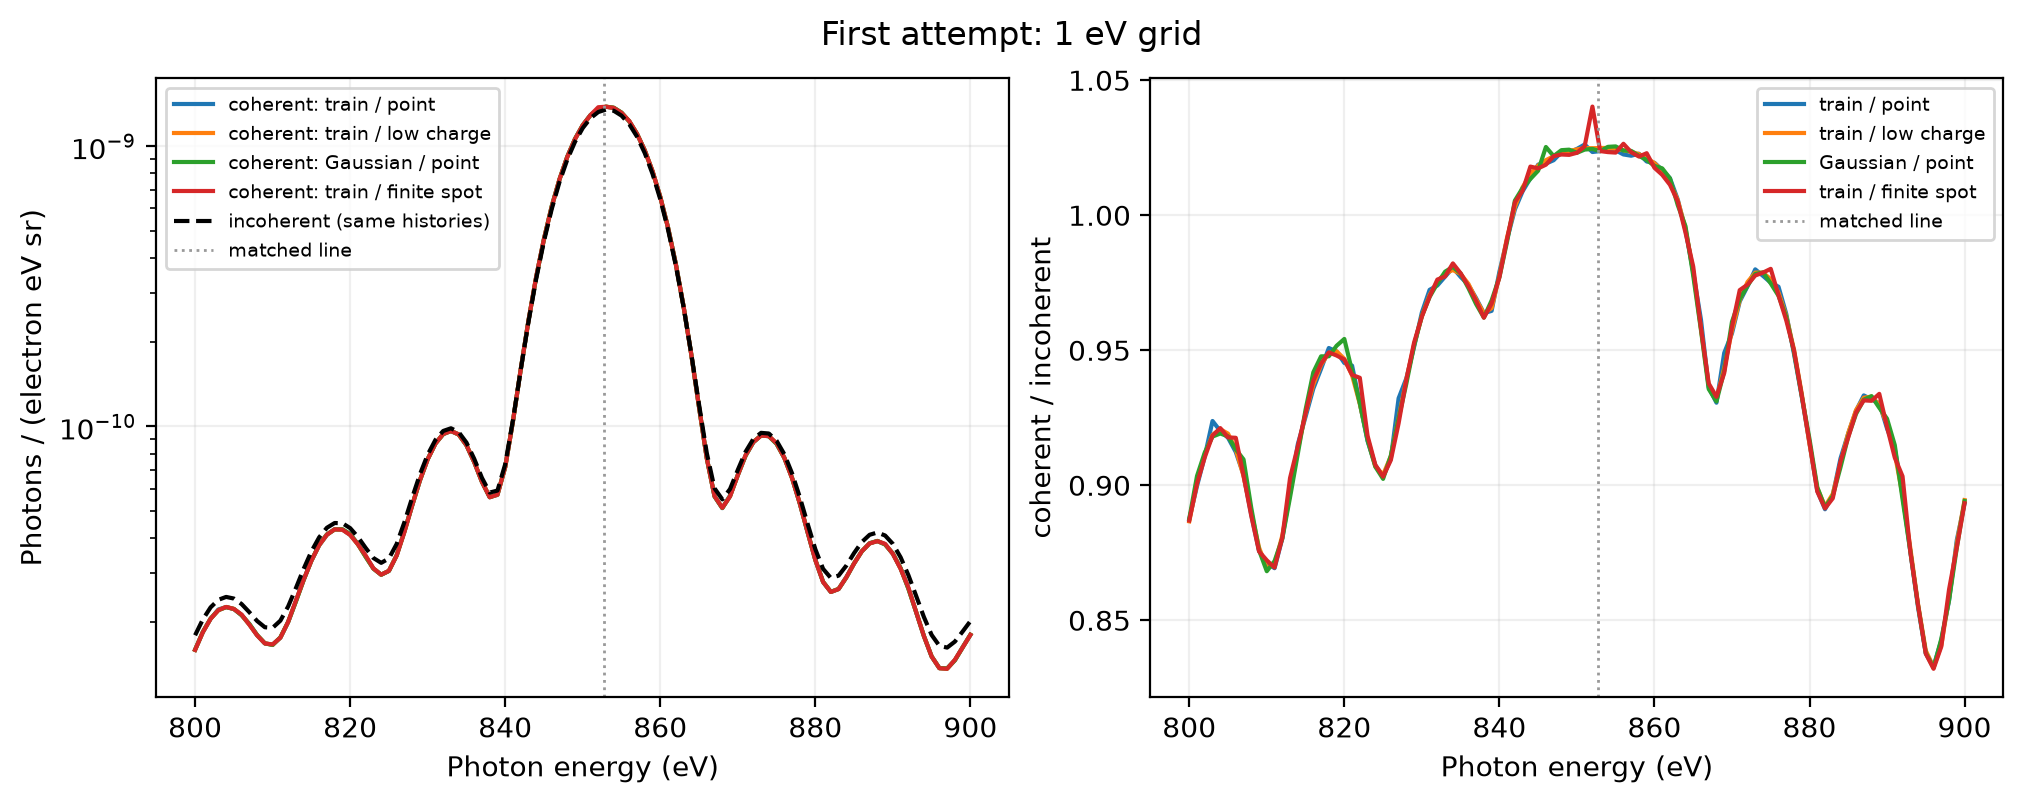

In [ ]:
plot_spectra(coarse, "First attempt: 1 eV grid")

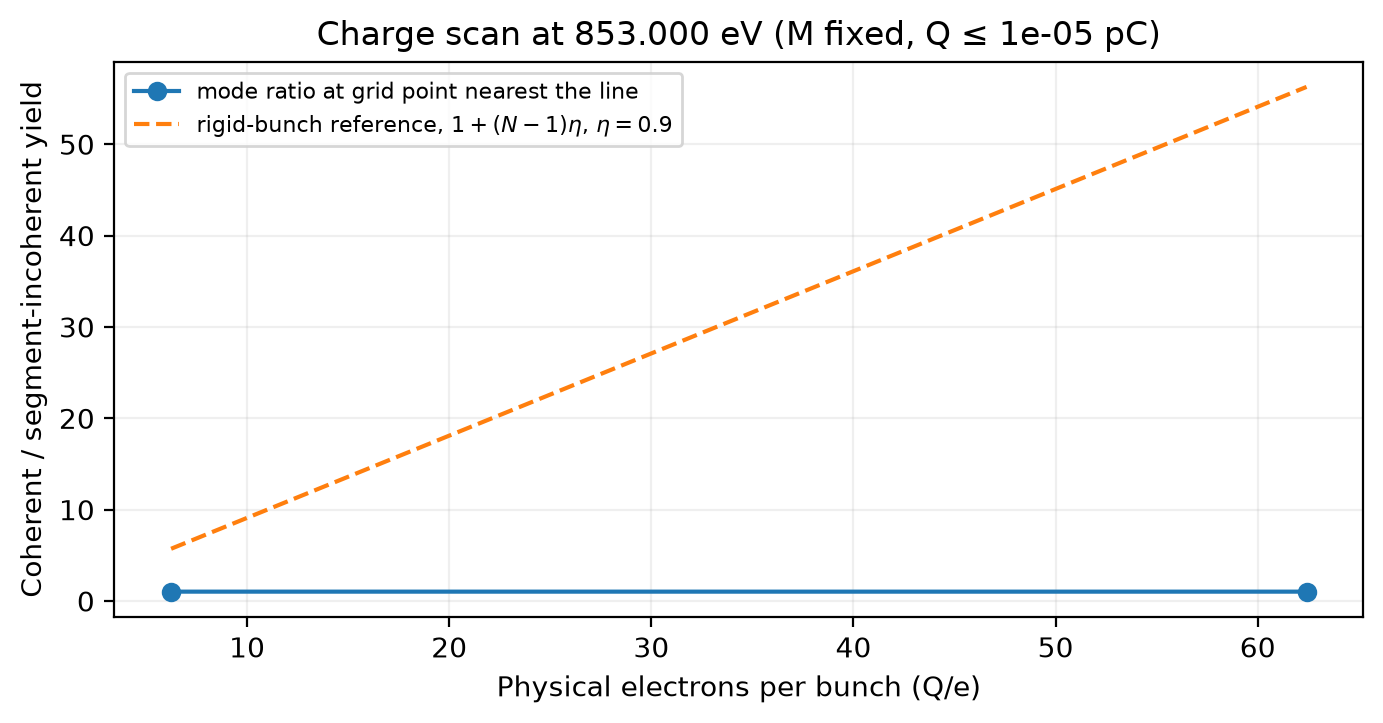

In [ ]:
plot_charge_scan(coarse)

## **Wait... What?**

_There's no spike at the matched line._ The microtrain looks no
more coherent than the 1 fs Gaussian, and the charge scan sits nowhere
near the reference. The microbunches are spaced at exactly the line's
optical period, so where did the enhancement go?

### What's going wrong (computationally)

A microtrain's form factor is a comb. Near the matched harmonic
$\omega_0$, its envelope sets how quickly coherence falls off:

$$
|F(\omega_0+\delta\omega)|^2 \approx \eta\,\exp\!\left[-(\delta\omega\,\sigma_\mathrm{env})^2\right].
$$

The **peak height** is $\eta$ for any envelope, but the **width** is about
$\hbar/\sigma_\mathrm{env}$: roughly 0.66 eV for a 1 fs train and 0.066 eV
for 10 fs. A longer train gives a proportionally narrower coherent line.

The coherent estimator evaluates each electron's arrival phase _at_ each
grid energy; it does not average over a bin. With 1 eV spacing, the
nearest grid point can sit a few tenths of an eV from the line, and a
10 fs comb contributes almost nothing there. The physics is fine; we
sampled the spectrum too coarsely to see it.

In [ ]:
detuning_eV = float(energy_eV[np.argmin(np.abs(energy_eV - line_eV))] - line_eV)
print(f"matched line {line_eV:.3f} eV; nearest grid point is {detuning_eV:+.3f} eV away")
for _sigma_fs in (1.0, 10.0):
    _retained = 0.9 * np.exp(-((detuning_eV * _sigma_fs / hbar_eV_fs) ** 2))
    print(
        f"{_sigma_fs:>4g} fs envelope: line width ~{hbar_eV_fs / _sigma_fs:.3f} eV, "
        f"|F|^2 at nearest grid point = {_retained:.3g}"
    )

matched line 852.769 eV; nearest grid point is +0.231 eV away
   1 fs envelope: line width ~0.658 eV, |F|^2 at nearest grid point = 0.795
  10 fs envelope: line width ~0.066 eV, |F|^2 at nearest grid point = 3.87e-06


## Let's try again

Keep the 1 eV grid for context, but add a 5 meV window around the matched
line, well below $\hbar/\sigma_\mathrm{env}$. Everything else, including
seed and history count, is unchanged.

In [ ]:
assert tables_ready
fine_eV = np.union1d(energy_eV, line_eV + np.linspace(-0.6, 0.6, 441))
samples, elapsed = run_all(fine_eV, "Scoring coherent CXR (refined grid)")

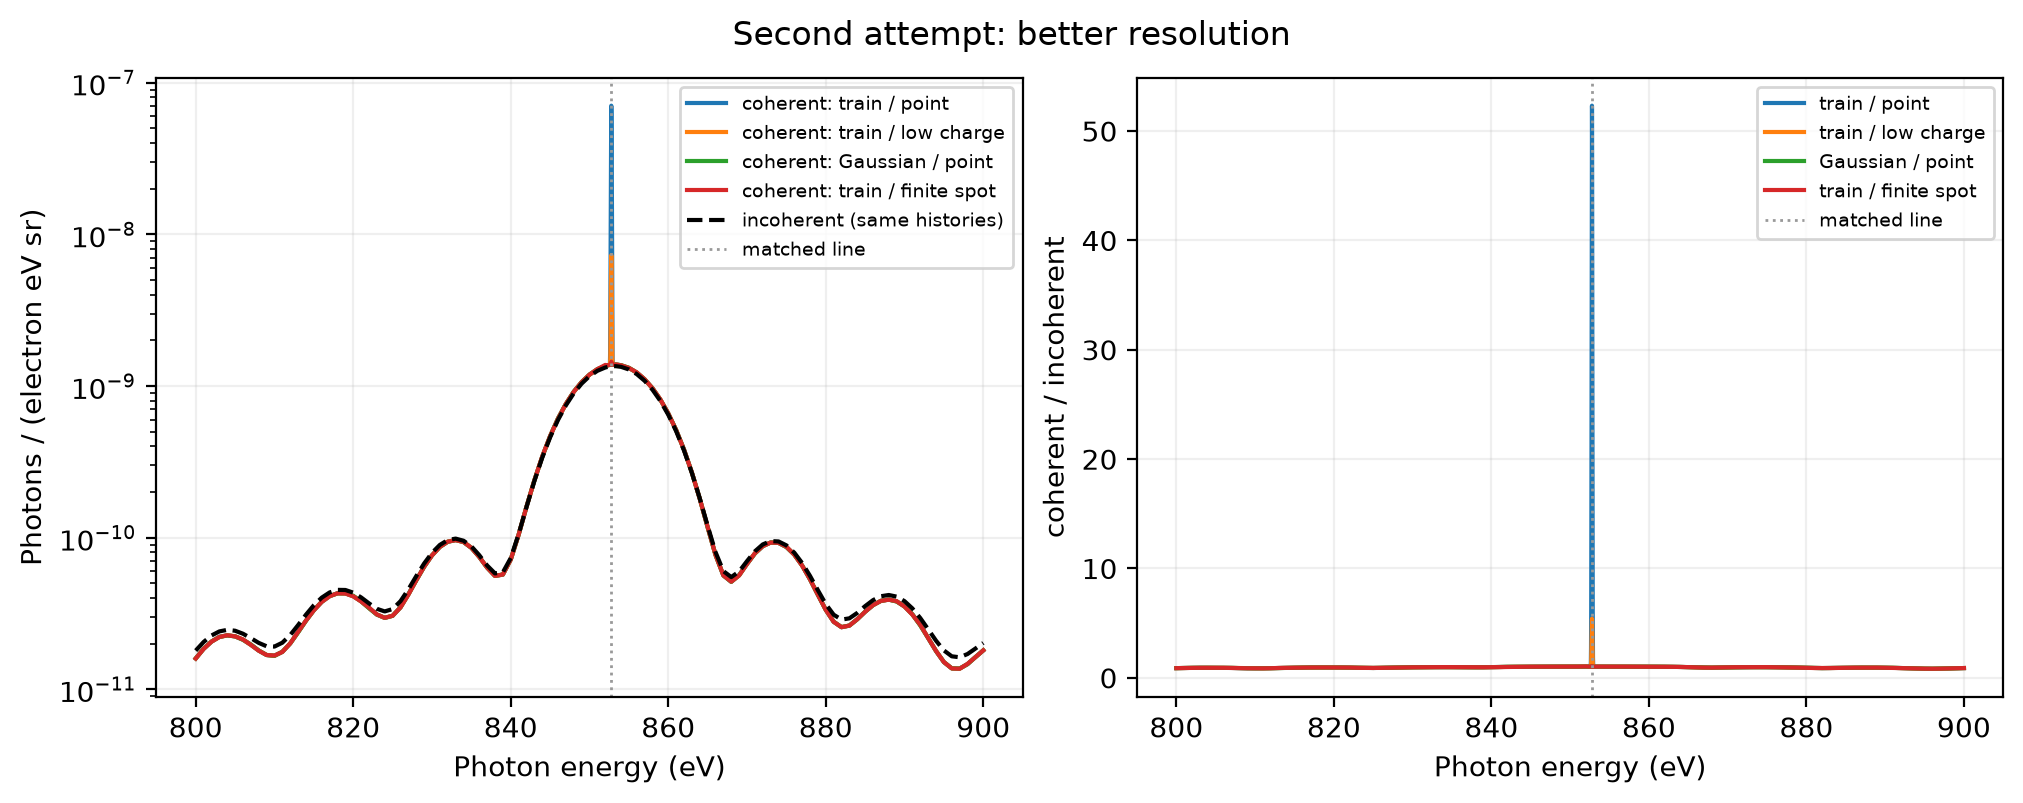

In [ ]:
plot_spectra(samples, "Second attempt: better resolution")

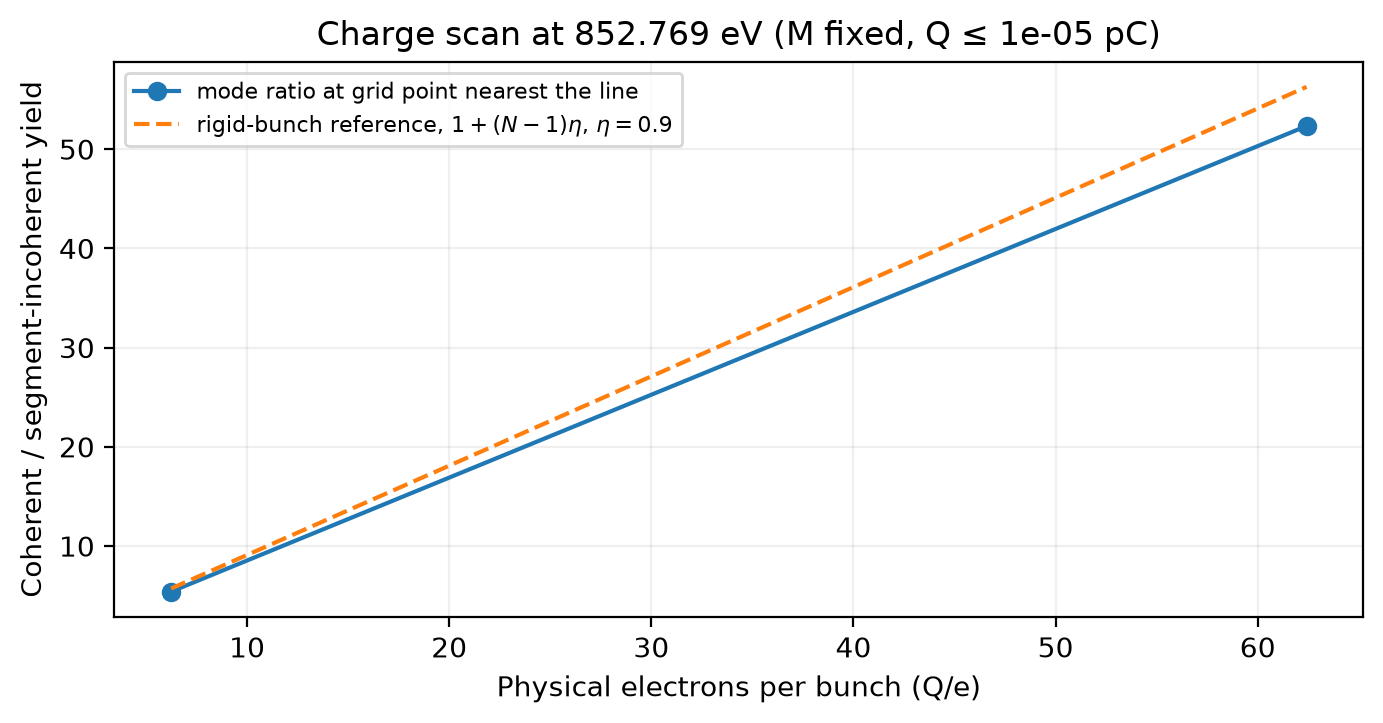

In [ ]:
plot_charge_scan(samples)

## Line width versus train length

Zoom in on the line and compare the 10 fs train with an otherwise
identical 1 fs train.

In [ ]:
assert tables_ready
trains = {
    "10 fs train": samples["train / point"],
    "1 fs train": simulate_case(make_train(1.0), energies_eV=fine_eV),
}

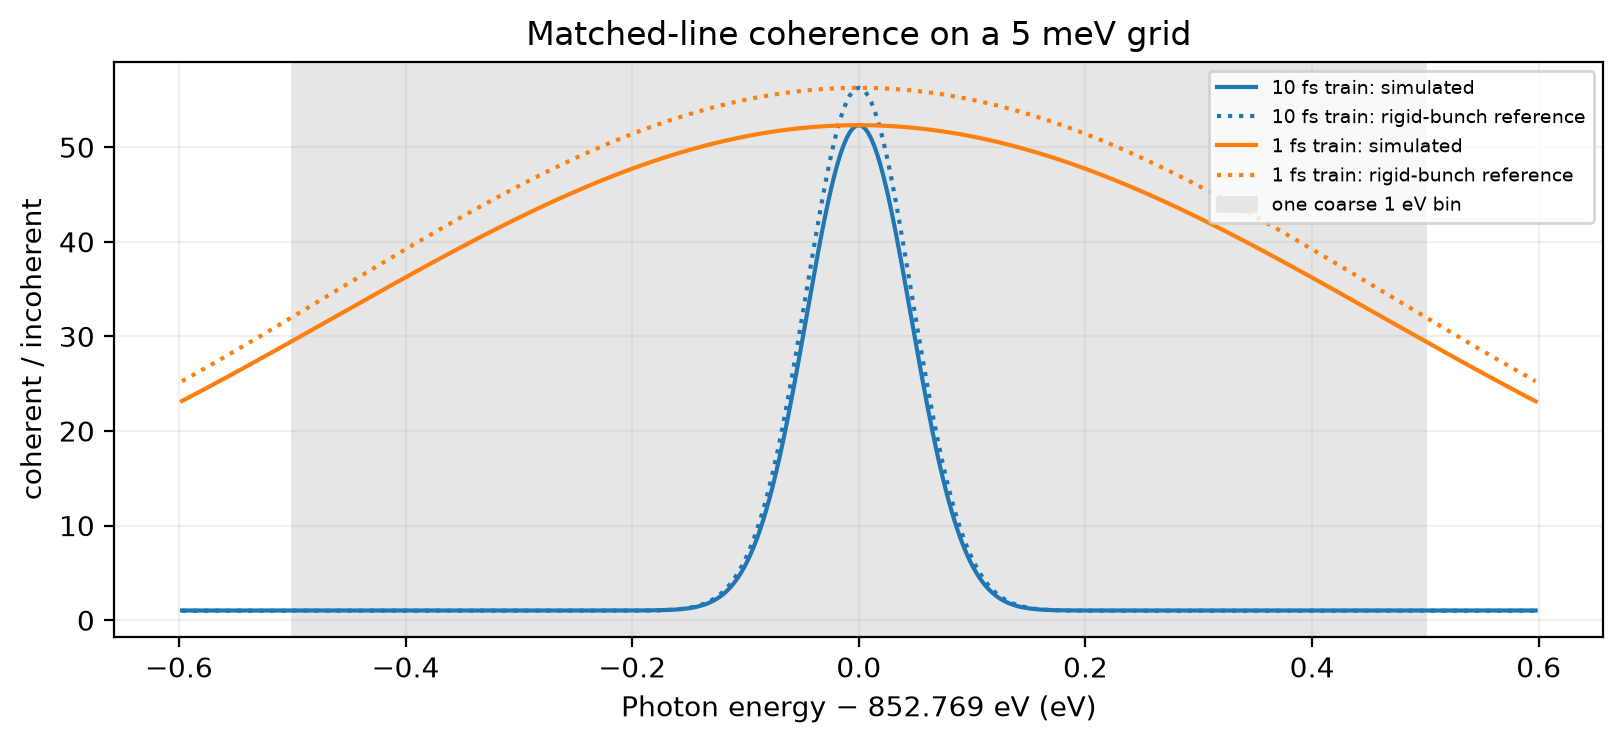

In [ ]:
fig_fine, _ax = plt.subplots(figsize=(8.0, 3.6), layout="constrained")
for (_label, _result), _sigma_fs in zip(trains.items(), (10.0, 1.0), strict=True):
    _detune = _result.cxr.incoherent.photon_energy_eV - line_eV
    _window = np.abs(_detune) <= 0.6
    _line = _ax.plot(_detune[_window], mode_ratio(_result)[_window], label=f"{_label}: simulated")[
        0
    ]
    _reference = 1 + (physical_electrons - 1) * 0.9 * np.exp(
        -((_detune[_window] * _sigma_fs / hbar_eV_fs) ** 2)
    )
    _ax.plot(
        _detune[_window],
        _reference,
        ls=":",
        color=_line.get_color(),
        label=f"{_label}: rigid-bunch reference",
    )
_ax.axvspan(-0.5, 0.5, color="0.9", zorder=0, label="one coarse 1 eV bin")
_ax.set(
    xlabel=f"Photon energy − {line_eV:.3f} eV (eV)",
    ylabel="coherent / incoherent",
    title="Matched-line coherence on a 5 meV grid",
)
_ax.grid(alpha=0.2)
_ax.legend(fontsize=7)
fig_fine  # noqa: B018

Expect both trains to reach a similar matched-line peak, with the 10 fs
line about ten times narrower. Compare each simulated curve with its
dotted rigid-bunch reference; scattering and the finite PXR linewidth
pull the simulation below it. The _integrated_ coherent yield over the
line scales roughly as $1/\sigma_\mathrm{env}$, and that part is physical:
a spectrometer with 1 eV resolution would also see the 10 fs train
diluted by about 0.07 eV / 1 eV, and the detector's finite angular
acceptance shifts the PXR line slightly with angle, spreading it further.

Practical rule: when a coherent feature may be narrower than your grid
spacing, refine the grid around the resolved line before drawing
conclusions. Keep spacing well below $\hbar/\sigma_\mathrm{env}$.

## Reading the spectra

Each result holds incoherent and coherent spectra scored from the **same**
transported histories, so their ratio isolates the coherent cross terms
rather than seed-to-seed noise. That ratio has no universal upper bound of
$N$. It also includes intra-electron coherence between segments, which the
incoherent mode discards.

- **Gaussian, 1 fs.** $\omega\sigma_t \approx 1300$ at 850 eV, so
  inter-electron terms vanish. Any remaining enhancement is intra-electron.
- **Microtrain.** Enhancement is confined to a line of width
  $\sim\hbar/\sigma_\mathrm{env}$ at the matched energy.
- **Finite spot.** For an independent Gaussian spot of RMS $\sigma_\perp$,
  the transverse factor is approximately
  $F_\perp = \exp[-|\mathbf q_\perp|^2\sigma_\perp^2]$ with
  $\mathbf q_\perp = (\omega\hat{\mathbf n}/c + \mathbf g)_\perp$.
  At X-ray wavenumbers even a sub-nm spot suppresses coherence strongly.

Signed pair estimators are noisy where the signal is near zero. Read the
ratio only where the incoherent line is well above background.

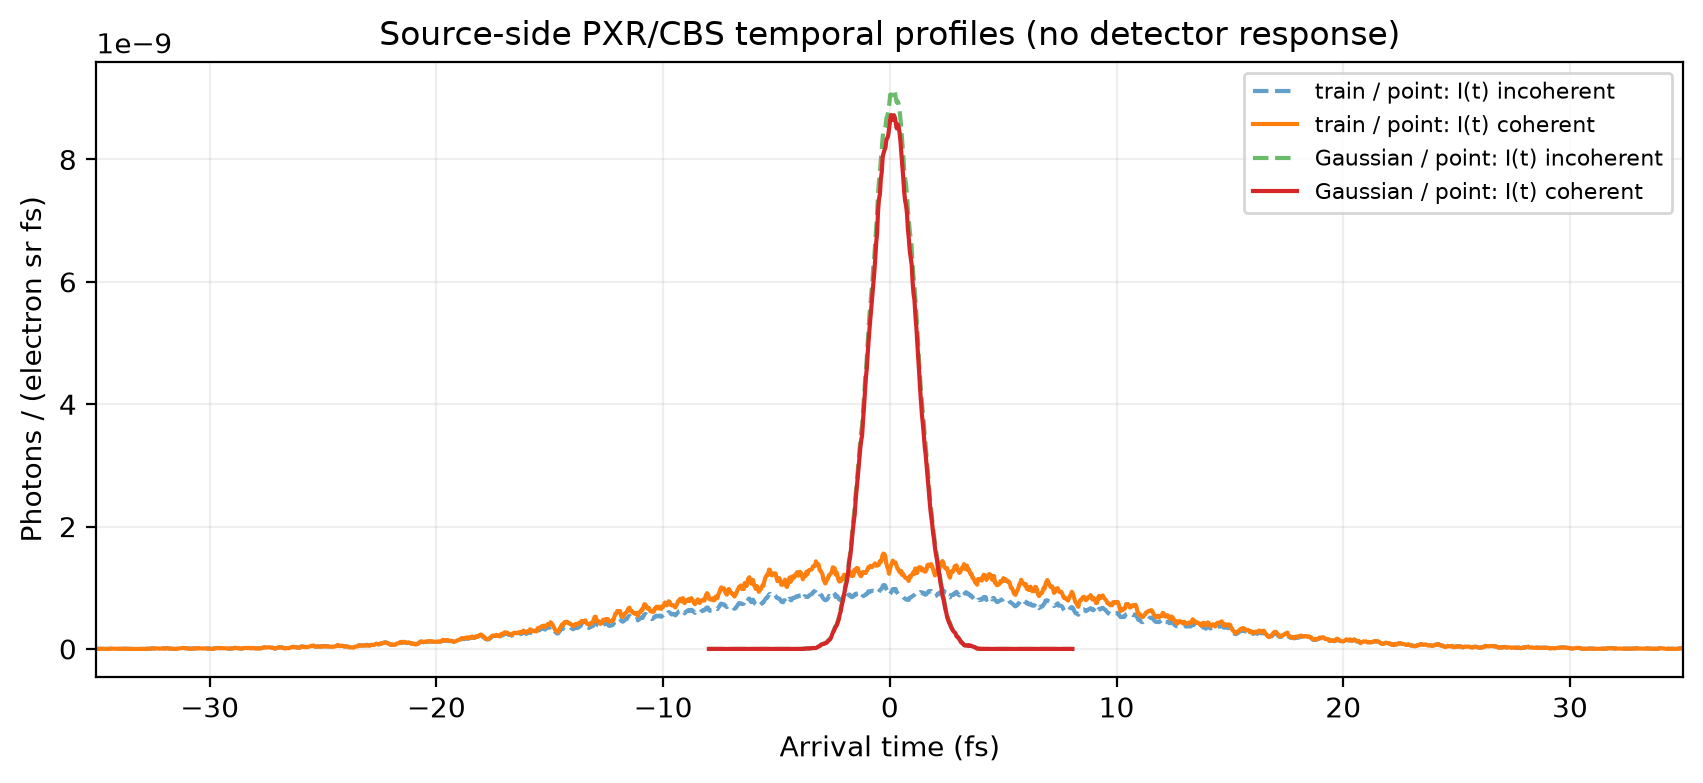

In [ ]:
fig_time, _ax = plt.subplots(figsize=(8.4, 3.8), layout="constrained")
for _label in ("train / point", "Gaussian / point"):
    temporal = samples[_label].temporal
    assert temporal is not None
    _ax.plot(
        temporal.time_fs,
        temporal.incoherent,
        ls="--",
        alpha=0.7,
        label=f"{_label}: I(t) incoherent",
    )
    if temporal.coherent is not None:
        _ax.plot(temporal.time_fs, temporal.coherent, label=f"{_label}: I(t) coherent")
_ax.set(
    xlabel="Arrival time (fs)",
    ylabel="Photons / (electron sr fs)",
    title="Source-side PXR/CBS temporal profiles (no detector response)",
)
_ax.grid(alpha=0.2)
_ax.legend(fontsize=8)
# Inspect the physical arrival window, rather than the entire FFT period.
_ax.set_xlim(-35, 35)
fig_time  # noqa: B018

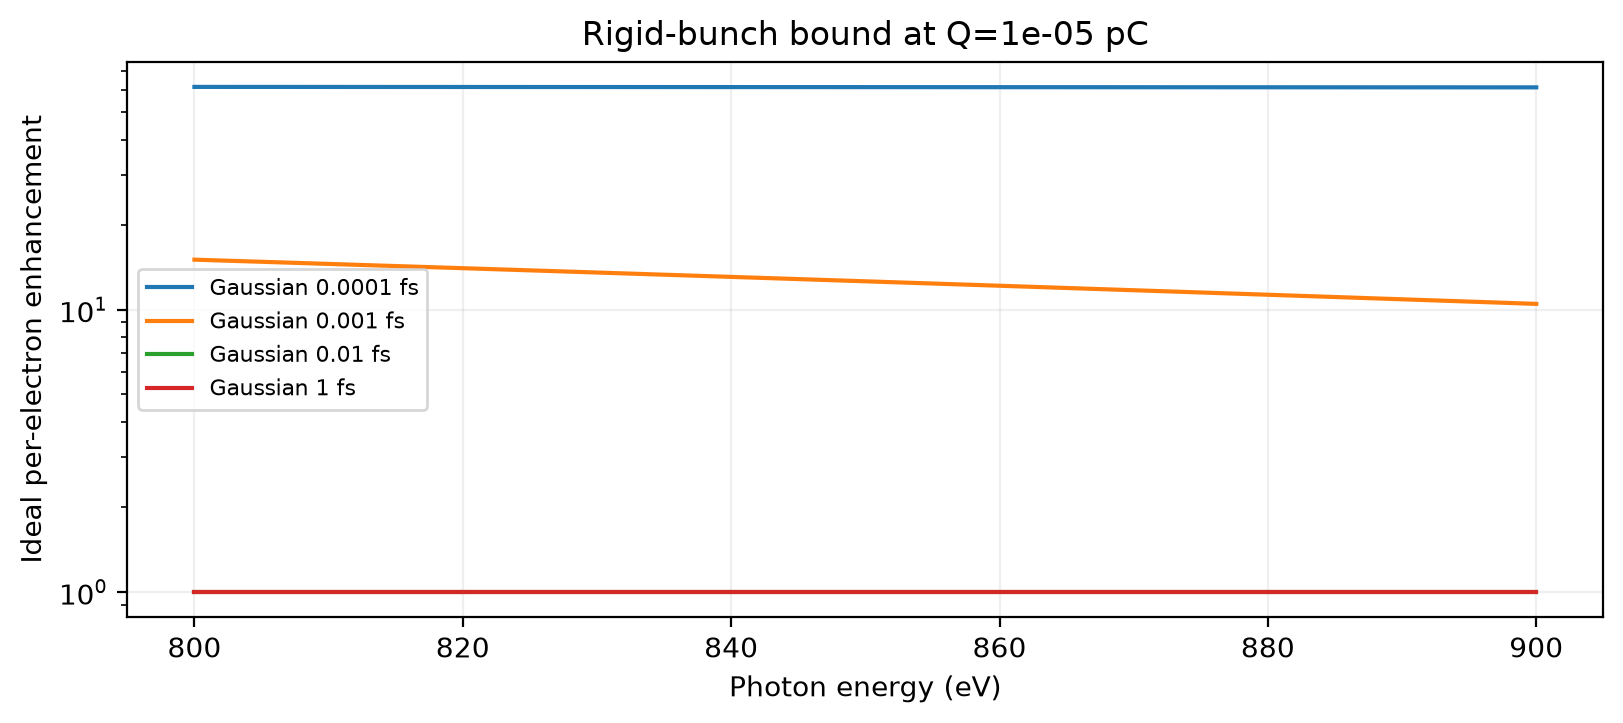

In [ ]:
# An analytic reference for identical emitters (not a bound on CXR mode ratios).
# It must not be interpreted as the Monte Carlo spectrum of a microtrain.
fig_form, _ax = plt.subplots(figsize=(8.0, 3.5), layout="constrained")
for sigma_fs in (0.0001, 0.001, 0.01, 1.0):
    fz = np.exp(-((energy_eV * sigma_fs / hbar_eV_fs) ** 2))
    _ax.plot(energy_eV, 1 + (physical_electrons - 1) * fz, label=f"Gaussian {sigma_fs:g} fs")
_ax.set(
    xlabel="Photon energy (eV)",
    ylabel="Ideal per-electron enhancement",
    yscale="log",
    title=f"Rigid-bunch bound at Q={charge_pc:g} pC",
)
_ax.grid(alpha=0.2)
_ax.legend(fontsize=8)
fig_form  # noqa: B018

## Interpretation and validation scope

The form-factor plot is a **rigid-bunch reference**: $N$ identical emitters
with fields that are exactly equal. Real electrons scatter along different
trajectories, so the simulated enhancement need not follow that curve. A
full-depth, zero-jitter microtrain targets a chosen form factor _at the
resolved basal line only_. In the charge scan, the dashed line uses
$|F|^2 = \eta = 0.9$ as that reference. A finite transverse spot multiplies
the longitudinal factor only under the model's offset-independence
assumptions.

`Result.temporal` is an opt-in **source** diagnostic, not a detector
waveform or time-resolution model. Cross terms can make individual coherent
bins negative, so never clip them before integrating. The energy bandwidth
limits the time resolution, and the inverse-FFT period is not a measured
pulse duration.

### Variations

- Reduce `retained_coherence` or add `timing_jitter_fs` and watch the
  matched-line enhancement fall.
- Set `modulation_depth` below 1 to mix an unmodulated background into the
  train.
- Change `observation_deg`. The microtrain re-matches its spacing to the
  new line on every run, and `line_eV` moves the fine window with it. In a
  sweep, each case resolves its own spacing from that case's detector
  angle.

This notebook demonstrates modeled behavior. It is **not** independent
validation or sign-off. See
[coherent emission](../../physics/radiation-physics/coherent-emission.md),
[temporal intensity profile](../../physics/radiation-physics/temporal-intensity-profile.md),
[longitudinal structure](../../physics/beam-transport/longitudinal-structure.md),
and the validation pages
[inter-electron decoherence](../../validation/radiation-physics/coherent-inter-electron-decoherence.md)
and [physical bunch population](../../validation/radiation-physics/coherent-physical-bunch-population.md).

## Continue learning

See [Transition radiation](10-transition-radiation.ipynb)
and [Coherent-emission physics](../../physics/radiation-physics/coherent-emission.md).

{download}`Download canonical Marimo notebook <../17-classical-coherent-phase-tracking.py>`